# Поиск экзопланеты "Кеплер"
Павлова Дарья, Лукянинко Яна, Горчакова Надежда (451 группа соцфак)


### *Историческая справка*
  Кеплер - это космическая обсерватория НАСА, орбитальный телескоп со сверхчувствительным фотометром, специально предназначенный для поиска экзопланет, подобных Земле. Это первый космический аппарат, созданный с такой целью. Он назван в честь немецкого математика и астронома Иоганна Кеплера, открывшего законы движения планет. Обсерватория могла одновременно наблюдать более чем 100 тыс. звёзд. Наличие планеты у звезды определяется по периодическим изменениям яркости последней, вызываемым прохождениями планеты перед звездой.
  
  Кеплер подтвердил 1284 новые экзопланеты по состоянию на май 2016 года. По состоянию на октябрь 2017 года насчитывается более 3000 подтвержденных экзопланет (с использованием всех методов обнаружения, в том числе наземных). Телескоп по-прежнему активен и продолжает собирать новые данные о своей расширенной миссии.


# Набор данных и описание
Этот набор данных представляет собой кумулятивную запись всех наблюдаемых «объектов, представляющих интерес» Кеплера — в основном, всех примерно 10 000 кандидатов в экзопланеты, за которыми Кеплер наблюдал.

Этот набор данных имеет обширный словарь данных, с которым можно ознакомиться здесь: https://exoplanetarchive.ipac.caltech.edu/docs/API_kepcandidate_columns.html. Выделяются следующие столбцы:

kepoi_name — это цель, идентифицированная проектом «Кеплер», которая отображает по меньшей мере одну транзитоподобную последовательность в фотометрии временных рядов Кеплера, которая, по-видимому, имеет астрофизическое происхождение и первоначально согласуется с гипотезой планетарного транзита.

kepler_name - предназначены для четкого обозначения класса объектов, которые были подтверждены или подтверждены как планеты — шаг вперед к обозначению кандидата в планеты.

koi_disposition - описательная склонность этого кандидата в экзопланеты. Один из КАНДИДАТОВ, ЛОЖНОПОЛОЖИТЕЛЬНЫЙ, НЕ ДИСПОЗИЦИОННЫЙ и НЕ ПОДТВЕРЖДЕННЫЙ.

koi_pdisposition: Отношение анализа данных Кеплера к этому кандидату в экзопланеты. Один из ЛОЖНОПОЛОЖИТЕЛЬНЫХ, НЕ ДИСПОЗИЦИОННЫХ, и КАНДИДАТ.

koi_score: Значение от 0 до 1, указывающее на уверенность в диспозиции KOI. Для CANDIDATE более высокое значение указывает на большую уверенность к его диспозиции, в то время как для ЛОЖНЫХ POSITIVE более высокое значение указывает на меньшую уверенность к его диспозиции.

Необходимо установить следующее:
1. Как часто экзопланеты, подтвержденные в существующей литературе, опровергаются измерениями Кеплера?
2. Какие общие характеристики экзопланет (которые мы можем найти) можно получить из этого набора данных?
3. Каким экзопланетам присваиваются названия в литературе? Каково распределение оценок достоверности?






In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from google.colab import files
uploaded = files.upload()
planeti = pd.read_csv('planeti.csv', delimiter=';')


Saving planeti.csv to planeti (1).csv


In [ ]:
planeti

,"rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,koi_time0bk_err1,koi_time0bk_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_prad,koi_prad_err1,koi_prad_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr,koi_tce_plnt_num,koi_tce_delivname,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag"
0,"1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CA..."
1,"2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CA..."
2,"3,10811496,K00753.01,,FALSE POSITIVE,FALSE POS..."
3,"4,10848459,K00754.01,,FALSE POSITIVE,FALSE POS..."
4,"5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CA..."
...,...
9559,"9560,10031643,K07984.01,,FALSE POSITIVE,FALSE ..."
9560,"9561,10090151,K07985.01,,FALSE POSITIVE,FALSE ..."
9561,"9562,10128825,K07986.01,,CANDIDATE,CANDIDATE,0..."
9562,"9563,10147276,K07987.01,,FALSE POSITIVE,FALSE ..."


Узнаем объем информации(первые 1000 строк):

In [ ]:
nRowsRead = 1000
df1 = pd.read_csv('planeti.csv', delimiter=',', nrows = nRowsRead)
df1.dataframeName = 'planeti.csv'
nRow, nCol = df1.shape
print(f'Есть {nRow} строк и {nCol} столбцов')

Есть 1000 строк и 50 столбцов


#Следующие процедуры предназначены для создание графиков. Нажмите, чтобы открыть

In [ ]:
def plotPerColumnDistribution(df, nGraphShown, nGraphPerRow):
    nunique = df.nunique()
    df = df[[col for col in df if nunique[col] > 1 and nunique[col] < 50]]
    nRow, nCol = df.shape
    columnNames = list(df)
    nGraphRow = (nCol + nGraphPerRow - 1) / nGraphPerRow
    plt.figure(num = None, figsize = (6 * nGraphPerRow, 8 * nGraphRow), dpi = 80, facecolor = 'w', edgecolor = 'k')
    for i in range(min(nCol, nGraphShown)):
        plt.subplot(nGraphRow, nGraphPerRow, i + 1)
        columnDf = df.iloc[:, i]
        if (not np.issubdtype(type(columnDf.iloc[0]), np.number)):
            valueCounts = columnDf.value_counts()
            valueCounts.plot.bar()
        else:
            columnDf.hist()
        plt.ylabel('counts')
        plt.xticks(rotation = 90)
        plt.title(f'{columnNames[i]} (column {i})')
    plt.tight_layout(pad = 1.0, w_pad = 1.0, h_pad = 1.0)
    plt.show()

In [ ]:
def plotCorrelationMatrix(df, graphWidth):
    filename = df.dataframeName
    df = df.dropna('columns')
    df = df[[col for col in df if df[col].nunique() > 1]]
    if df.shape[1] < 2:
        print(f'No correlation plots shown: The number of non-NaN or constant columns ({df.shape[1]}) is less than 2')
        return
    corr = df.corr()
    plt.figure(num=None, figsize=(graphWidth, graphWidth), dpi=80, facecolor='w', edgecolor='k')
    corrMat = plt.matshow(corr, fignum = 1)
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.gca().xaxis.tick_bottom()
    plt.colorbar(corrMat)
    plt.title(f'Корелляионная матрица для {filename}', fontsize=15)
    plt.show()

In [ ]:
def plotScatterMatrix(df, plotSize, textSize):
    df = df.select_dtypes(include =[np.number])

    df = df.dropna('columns')
    df = df[[col for col in df if df[col].nunique() > 1]]
    columnNames = list(df)
    if len(columnNames) > 10:
        columnNames = columnNames[:10]
    df = df[columnNames]
    ax = pd.plotting.scatter_matrix(df, alpha=0.75, figsize=[plotSize, plotSize], diagonal='kde')
    corrs = df.corr().values
    for i, j in zip(*plt.np.triu_indices_from(ax, k = 1)):
        ax[i, j].annotate('Corr. coef = %.3f' % corrs[i, j], (0.8, 0.2), xycoords='axes fraction', ha='center', va='center', size=textSize)
    plt.suptitle('Графики рассеивания и плотности')
    plt.show()

# Графики распределения выборочных столбцов


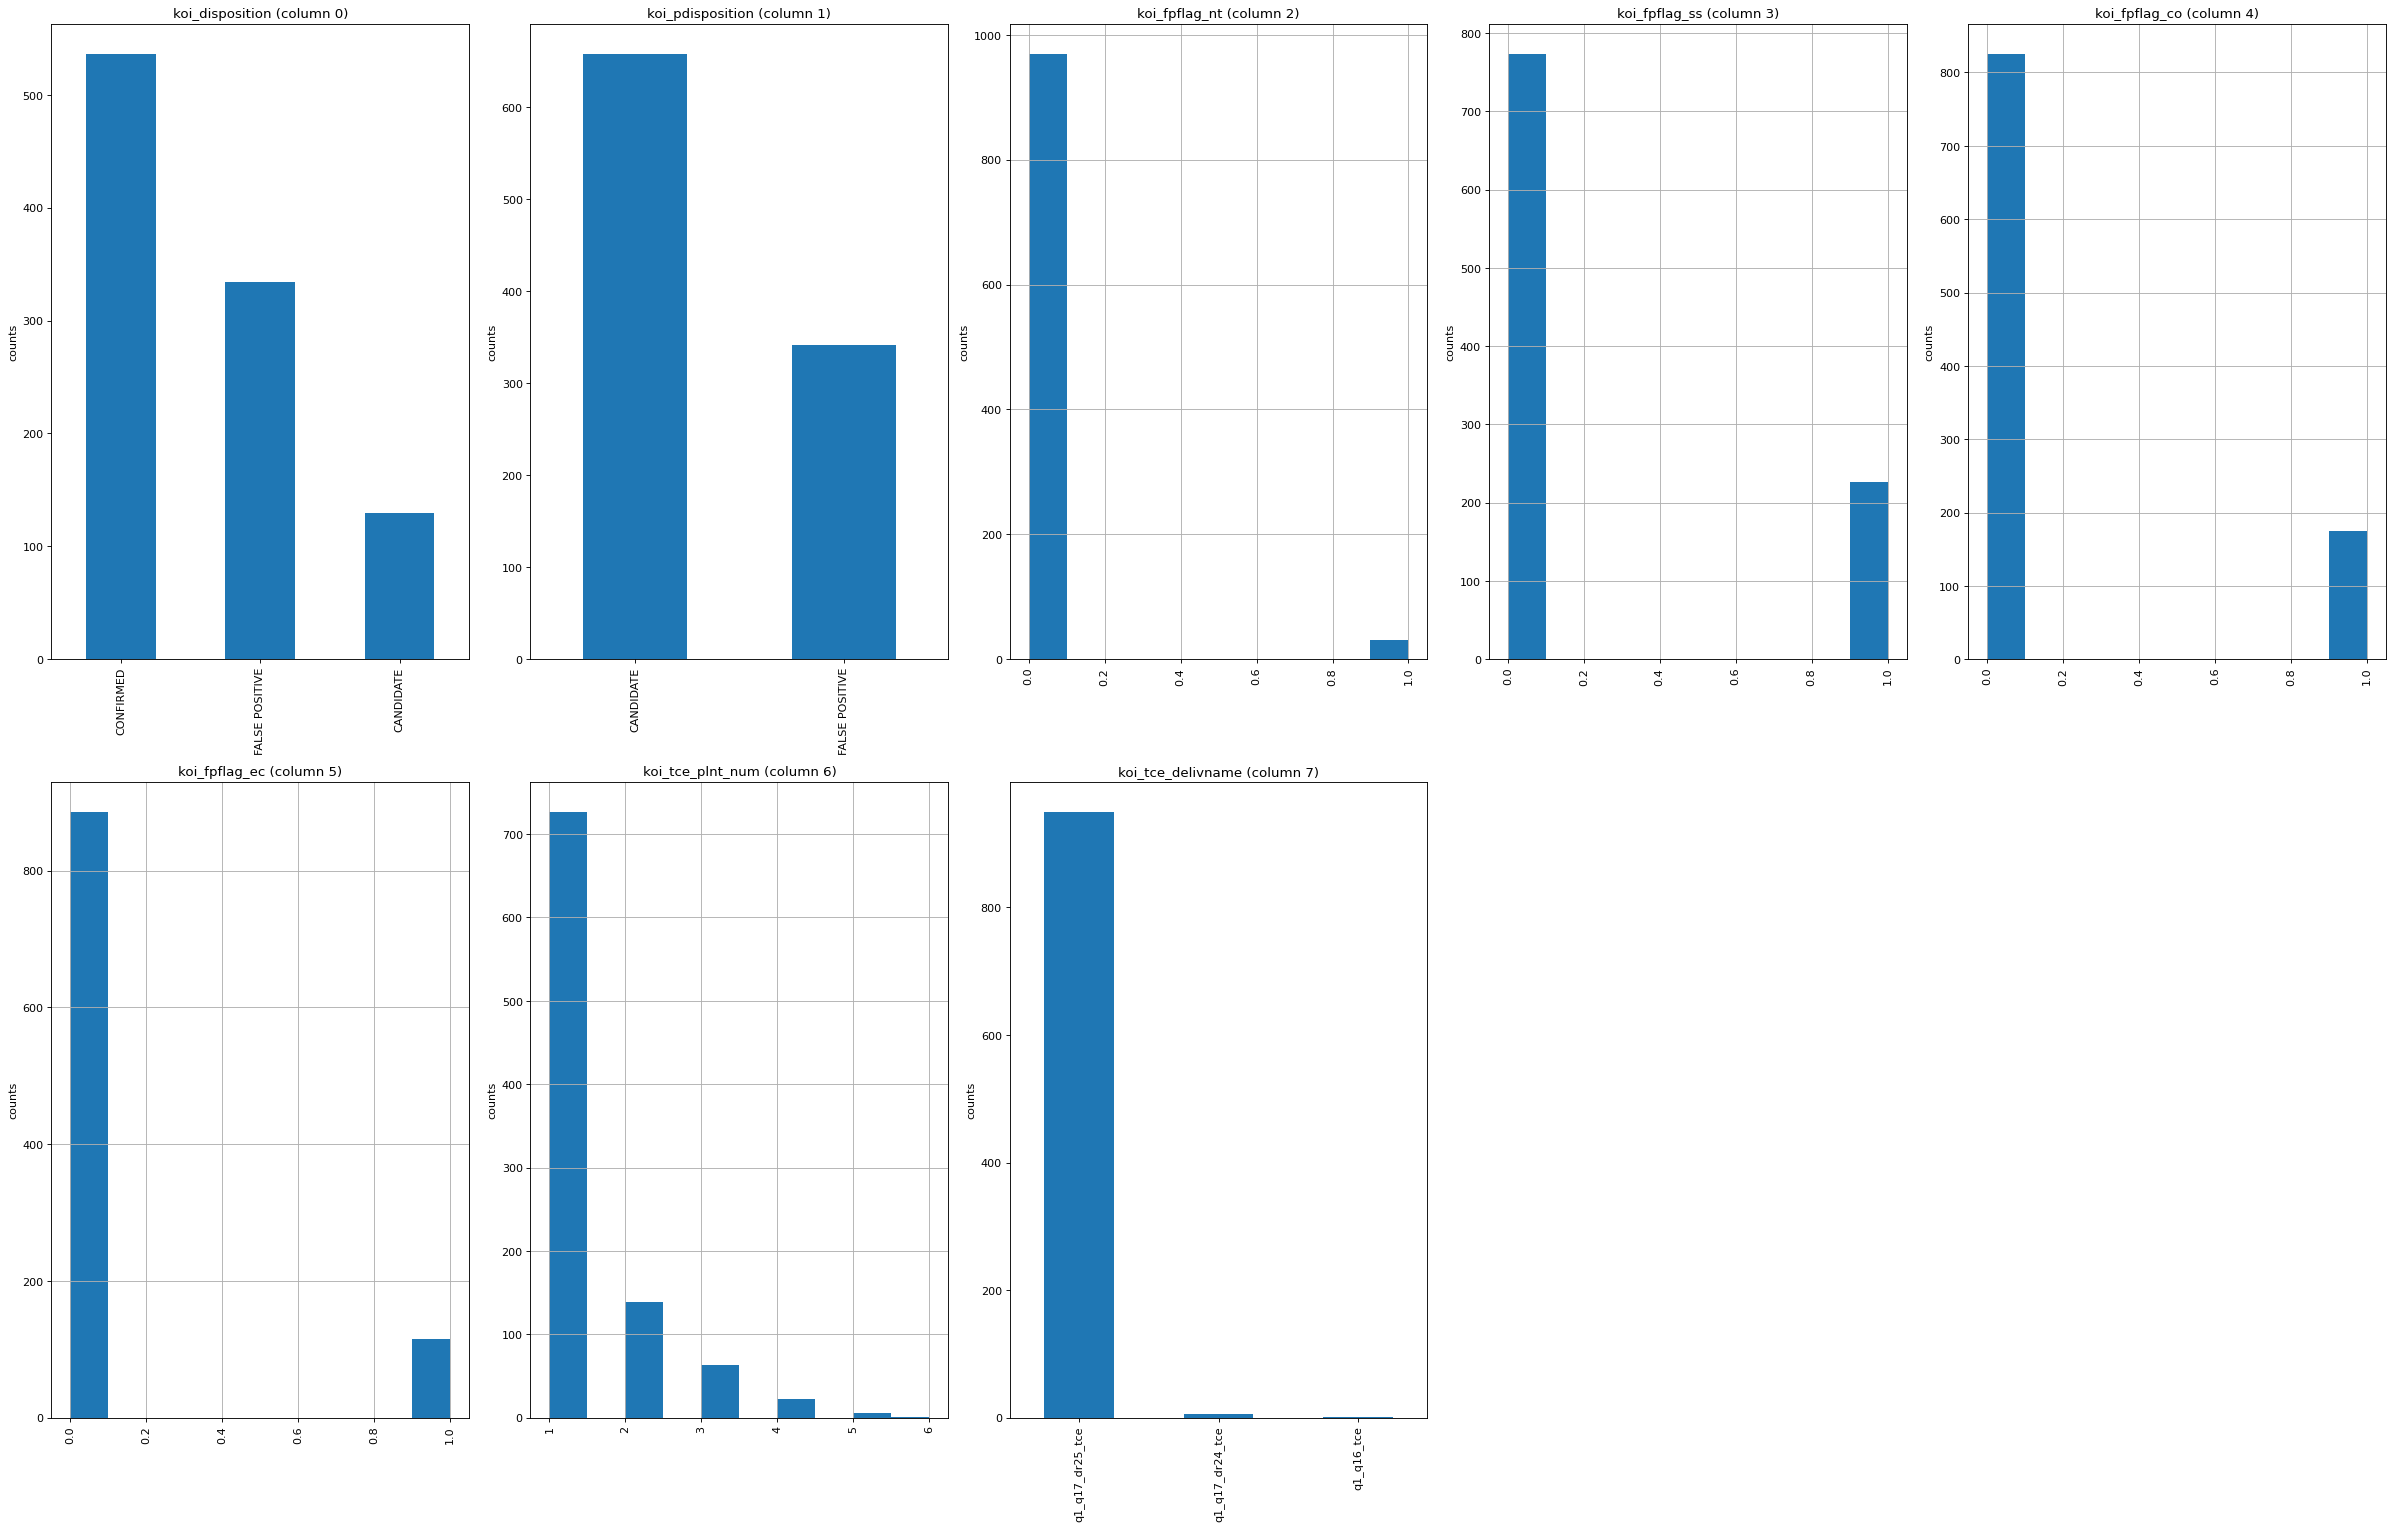

In [ ]:
plotPerColumnDistribution(df1, 10, 5)

# Корелляционная матрица:


<ipython-input-35-7c81238e9e31>:3: FutureWarning: In a future version of pandas all arguments of DataFrame.dropna will be keyword-only
  df = df.dropna('columns') # drop columns with NaN


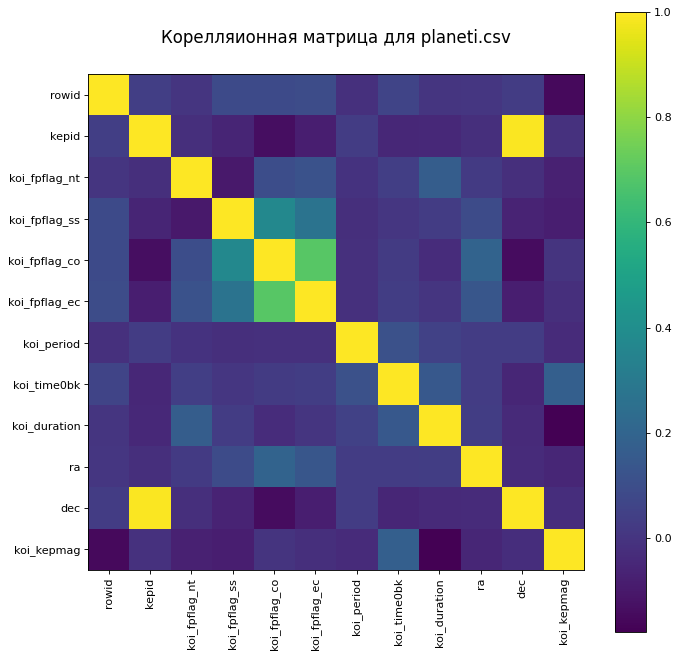

In [ ]:
plotCorrelationMatrix(df1, 10)

# Графики рассеивания и плотности:

<ipython-input-36-e8c88bf6ee43>:4: FutureWarning: In a future version of pandas all arguments of DataFrame.dropna will be keyword-only
  df = df.dropna('columns')


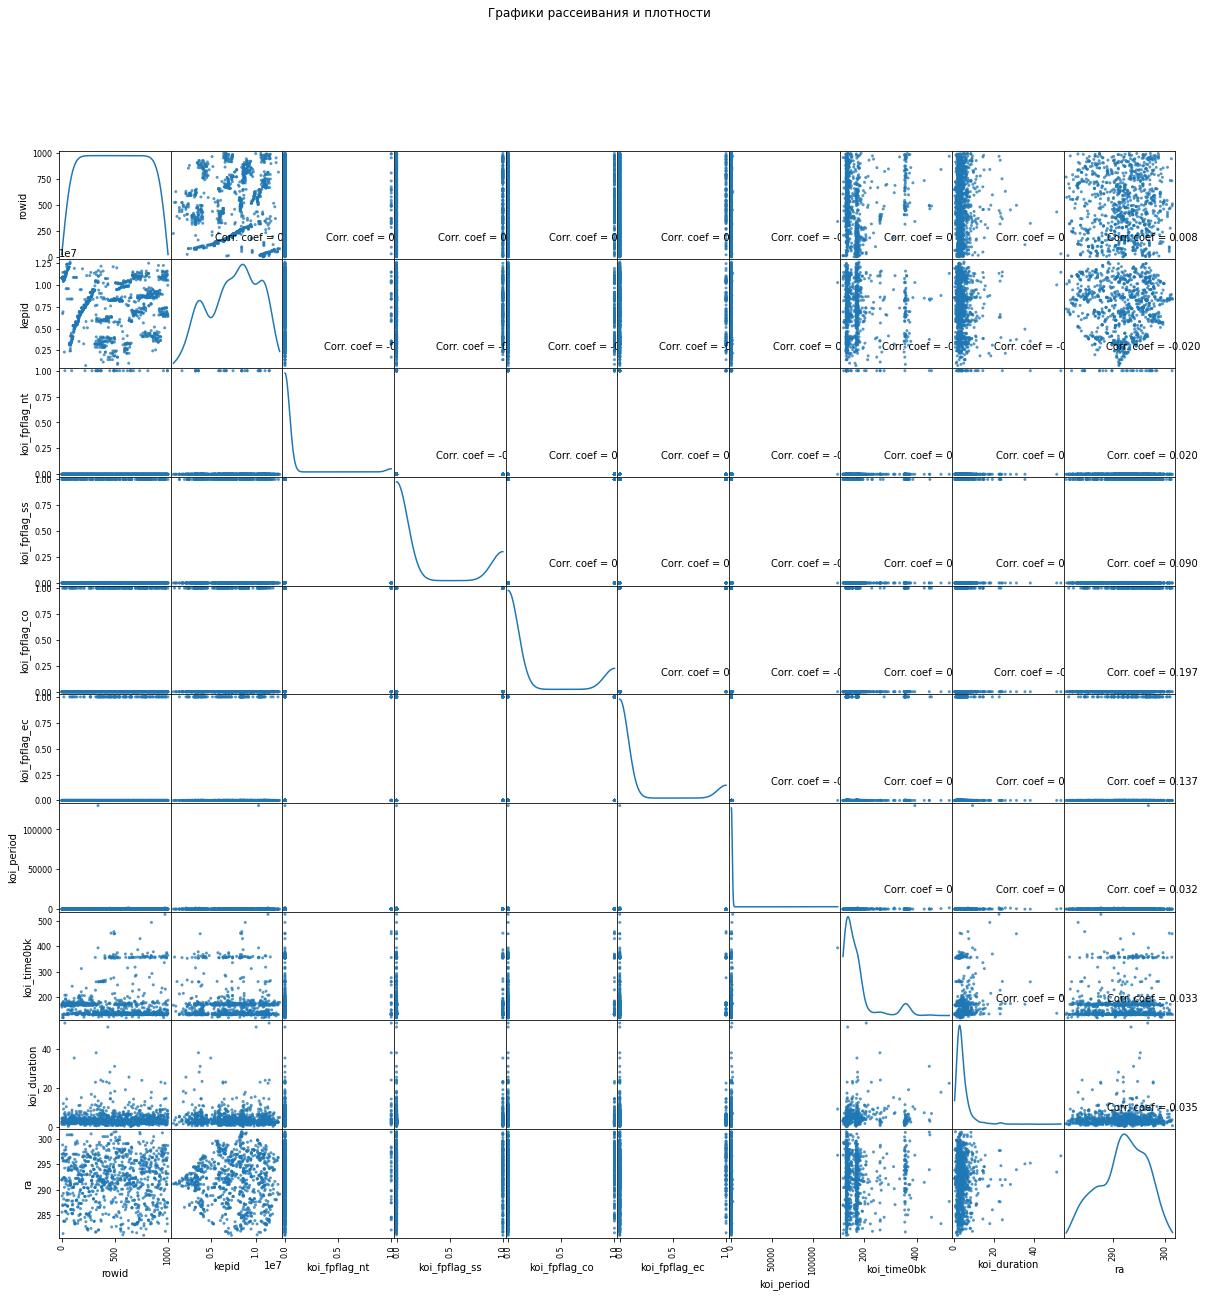

In [ ]:
plotScatterMatrix(df1, 20, 10)